# Machine Learning

## Research question
**What drives success for teams in the FIFA World Cup and what factors influence match outcomes?**

## Purpose of this notebook
The exploratory analysis in `05_EDA.ipynb` identified relationships between team performance, match events and World Cup success. This notebook moves from **description** to **prediction**.

The main machine-learning task is:

> **Can information that was available before a World Cup match help predict whether the match ends in a home-team win, draw or away-team win?**

The aim is to build a model whose inputs could genuinely have been known before each match, evaluate it on later tournaments that the model has not seen, and interpret which pre-match factors contain useful predictive information.

## Why the 2026 tournament-total performance datasets are not used as match predictors

The 2026 attacking, defending, goalkeeping, distribution, physical, movement and discipline datasets are extremely useful for EDA because they describe how teams performed during the tournament.

However, most of those values are **full-tournament totals or summaries**. If the model used a team's final 2026 goals, xG, passes or clean sheets to predict a match played earlier in the same tournament, it would indirectly receive information from matches that happened later.

That is **data leakage**.

Data leakage can make a model appear much more accurate than it would be in a genuine forecasting situation. Therefore:

- the 2026 performance datasets remain part of the project's explanatory EDA;
- they are **not** used as predictors in this match-outcome model;
- the ML features below are calculated only from matches that occurred **before** the match being predicted.

This distinction is important: EDA can examine associations using completed-tournament statistics, while predictive ML must respect what information would actually have been available at prediction time.

## Modelling strategy

The workflow is:

1. Load the cleaned international results dataset.
2. Keep completed matches and order them chronologically.
3. Convert the data temporarily to a team-level match history so each team has its own sequence of prior matches.
4. Create **pre-match rolling features** using only earlier matches.
5. Return to one row per World Cup match and calculate the difference between the two teams' pre-match features.
6. Split the World Cup matches **by time**, rather than randomly.
7. Establish a simple baseline.
8. Compare several classification models on the 2018 World Cup.
9. Select the strongest validation model using **macro F1** as the primary metric.
10. Refit the selected model using all data available through 2018.
11. Evaluate it once on the unseen 2022 and 2026 World Cups.
12. Use permutation importance to investigate which features carried the most predictive information.

### Why use a time-based split?
A random train/test split could place a later match in the training set while an earlier match from the same era appears in the test set. That is less representative of real forecasting. A chronological split is stricter: the model must use the past to predict the future.

## Importing libraries and locate the processed data


In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import seaborn as sns

plasma_palette = sns.color_palette(palette='plasma')
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=plasma_palette)

from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    log_loss,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)
from sklearn.inspection import permutation_importance

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 100)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')

RANDOM_STATE = 42

CURRENT_DIR = Path.cwd()
PROJECT_ROOT = CURRENT_DIR.parent if CURRENT_DIR.name == 'notebooks' else CURRENT_DIR
PROCESSED_DATA_DIR = PROJECT_ROOT / 'data' / 'processed'

print('Project root:', PROJECT_ROOT)
print('Processed data directory:', PROCESSED_DATA_DIR)
print('Directory exists:', PROCESSED_DATA_DIR.exists())

Project root: C:\Users\Hafsa\Desktop\Fifa-2026-World-Cup-Project
Processed data directory: C:\Users\Hafsa\Desktop\Fifa-2026-World-Cup-Project\data\processed
Directory exists: True


In [2]:

# Saving all ML plots.

PLOTS_DIR = PROJECT_ROOT / 'plots'
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

original_show = plt.show
plot_counter = 0

def save_and_show(*args, **kwargs):
    global plot_counter

    for fig_num in plt.get_fignums():
        fig = plt.figure(fig_num)
        plot_counter += 1

        filename = f'06_ML_plot_{plot_counter:02d}.png'

        fig.savefig(
            PLOTS_DIR / filename,
            dpi=300,
            bbox_inches='tight'
        )

        print(f'Saved: {filename}')

    return original_show(*args, **kwargs)

plt.show = save_and_show

print('ML plots will be saved to:', PLOTS_DIR.resolve())


ML plots will be saved to: C:\Users\Hafsa\Desktop\Fifa-2026-World-Cup-Project\plots


## Load and validate the modelling source

`results_clean.csv` is the main modelling source because it provides a long chronological history of international matches.

We first verify the columns required for modelling. We do **not** alter the processed CSV.

In [3]:
results_path = PROCESSED_DATA_DIR / 'results_clean.csv'
if not results_path.exists():
    raise FileNotFoundError(f'Could not find: {results_path}')

results = pd.read_csv(results_path, parse_dates=['date'])

required_columns = {
    'date', 'home_team', 'away_team', 'home_score', 'away_score',
    'tournament', 'neutral', 'match_completed'
}
missing_columns = required_columns - set(results.columns)

if missing_columns:
    raise ValueError(f'Missing required columns: {sorted(missing_columns)}')

print('Results shape:', results.shape)
print('Date range:', results['date'].min().date(), 'to', results['date'].max().date())
print('Missing required columns:', missing_columns)
print('Duplicate full rows:', results.duplicated().sum())

Results shape: (49509, 15)
Date range: 1872-11-30 to 2026-07-19
Missing required columns: set()
Duplicate full rows: 0


## Keep completed matches and define the target

Rolling form must be based on genuine completed matches. Rows without known scores are therefore excluded from the modelling history.

The target is defined from the perspective of the dataset's `home_team` field:

- **Home Win** — home score is greater than away score
- **Draw** — scores are equal
- **Away Win** — away score is greater than home score

For neutral World Cup matches, “home” and “away” are still useful labels for identifying the two sides; they do not automatically imply home-ground advantage.

In [4]:
completed = results[
    (results['match_completed'] == True) &
    results['home_score'].notna() &
    results['away_score'].notna()
].copy()

completed = completed.sort_values(['date', 'home_team', 'away_team']).reset_index(drop=True)
completed['match_id'] = np.arange(len(completed))

completed['target'] = np.select(
    [
        completed['home_score'] > completed['away_score'],
        completed['home_score'] == completed['away_score']
    ],
    ['Home Win', 'Draw'],
    default='Away Win'
)

print('Completed international matches:', len(completed))
print('\nOutcome distribution:')
print(completed['target'].value_counts())

Completed international matches: 49509

Outcome distribution:
target
Home Win    24261
Away Win    13991
Draw        11257
Name: count, dtype: int64


## Build a team-level chronological match history

The source data has one row per match. Rolling form is easier to calculate if each match temporarily contributes two rows:

- one from the home team's perspective;
- one from the away team's perspective.

For each team-match row we calculate goals for, goals against, win/draw indicators and goal difference. This is an **analytical transformation only**; it does not change the cleaned source file.

In [5]:
home_history = completed[
    ['match_id', 'date', 'home_team', 'away_team', 'home_score', 'away_score', 'tournament']
].copy()
home_history.columns = [
    'match_id', 'date', 'team', 'opponent', 'goals_for', 'goals_against', 'tournament'
]
home_history['is_home'] = 1

away_history = completed[
    ['match_id', 'date', 'away_team', 'home_team', 'away_score', 'home_score', 'tournament']
].copy()
away_history.columns = [
    'match_id', 'date', 'team', 'opponent', 'goals_for', 'goals_against', 'tournament'
]
away_history['is_home'] = 0

team_history = pd.concat([home_history, away_history], ignore_index=True)
team_history = team_history.sort_values(
    ['date', 'match_id', 'is_home'],
    ascending=[True, True, False]
).reset_index(drop=True)

team_history['win'] = (team_history['goals_for'] > team_history['goals_against']).astype(int)
team_history['draw'] = (team_history['goals_for'] == team_history['goals_against']).astype(int)
team_history['goal_difference'] = team_history['goals_for'] - team_history['goals_against']
team_history['is_world_cup'] = (team_history['tournament'] == 'FIFA World Cup').astype(int)
team_history['world_cup_win'] = team_history['win'] * team_history['is_world_cup']

print('Team-history rows:', len(team_history))
print('Expected rows:', len(completed) * 2)
print('Check passed:', len(team_history) == len(completed) * 2)

Team-history rows: 99018
Expected rows: 99018
Check passed: True


## Engineer leakage-safe pre-match features

This is the most important modelling step.

Every rolling statistic uses `.shift()` **before** calculating the feature. Shifting means the current match is removed from its own predictor values. Therefore the model cannot use the result or goals from the match it is trying to predict.

### Features created

**Recent form — previous 10 matches**
- win rate;
- draw rate;
- average goals scored;
- average goals conceded;
- average goal difference.

**Longer-term strength**
- win rate across all previous recorded international matches.

**World Cup experience**
- number of previous World Cup matches;
- win rate across previous World Cup matches.

**Recency**
- days since the team's previous recorded international match, capped at 365 days so very long historical gaps do not dominate the numerical scale.

The 10-match window balances recency with stability. It is not claimed to be the only possible window; it is a transparent modelling choice that can be revisited in future work.

In [6]:
grouped = team_history.groupby('team', sort=False)

team_history['prior_matches'] = grouped.cumcount()

rolling_inputs = ['win', 'draw', 'goals_for', 'goals_against', 'goal_difference']
for column in rolling_inputs:
    team_history[f'form10_{column}'] = grouped[column].transform(
        lambda s: s.shift(1).rolling(window=10, min_periods=1).mean()
    )

team_history['prior_win_rate'] = grouped['win'].transform(
    lambda s: s.shift(1).expanding().mean()
)

team_history['prior_world_cup_matches'] = grouped['is_world_cup'].transform(
    lambda s: s.shift(1).cumsum()
).fillna(0)

team_history['prior_world_cup_wins'] = grouped['world_cup_win'].transform(
    lambda s: s.shift(1).cumsum()
).fillna(0)

team_history['prior_world_cup_win_rate'] = np.where(
    team_history['prior_world_cup_matches'] > 0,
    team_history['prior_world_cup_wins'] / team_history['prior_world_cup_matches'],
    0
)

team_history['previous_match_date'] = grouped['date'].shift(1)
team_history['days_since_last_match'] = (
    team_history['date'] - team_history['previous_match_date']
).dt.days.clip(upper=365)

feature_components = [
    'prior_matches',
    'form10_win',
    'form10_draw',
    'form10_goals_for',
    'form10_goals_against',
    'form10_goal_difference',
    'prior_win_rate',
    'prior_world_cup_matches',
    'prior_world_cup_win_rate',
    'days_since_last_match'
]

print(team_history[
    ['date', 'team', 'opponent'] + feature_components
].head(12).to_string(index=False))

      date     team opponent  prior_matches  form10_win  form10_draw  form10_goals_for  form10_goals_against  form10_goal_difference  prior_win_rate  prior_world_cup_matches  prior_world_cup_win_rate  days_since_last_match
1872-11-30 Scotland  England              0         NaN          NaN               NaN                   NaN                     NaN             NaN                    0.000                     0.000                    NaN
1872-11-30  England Scotland              0         NaN          NaN               NaN                   NaN                     NaN             NaN                    0.000                     0.000                    NaN
1873-03-08  England Scotland              1       0.000        1.000             0.000                 0.000                   0.000           0.000                    0.000                     0.000                 98.000
1873-03-08 Scotland  England              1       0.000        1.000             0.000                 0.000

### Leakage check

A direct way to test the feature logic is to inspect a team's first few matches. Its first match should have no prior form, while later rows should only summarise earlier results.

We also require both teams to have at least **five prior international matches** before a World Cup match enters the modelling dataset. This avoids asking the model to interpret extremely unstable form estimates from teams with almost no recorded history.

In [7]:
sample_team = team_history['team'].value_counts().index[0]
sample = team_history[team_history['team'] == sample_team][
    ['date', 'team', 'goals_for', 'goals_against', 'prior_matches',
     'form10_win', 'form10_goals_for', 'form10_goals_against']
].head(6)

print('Leakage-check example team:', sample_team)
display(sample)

Leakage-check example team: Sweden


,date,team,goals_for,goals_against,prior_matches,form10_win,form10_goals_for,form10_goals_against
468,1908-07-12,Sweden,11,3,0,NaN,NaN,NaN
479,1908-10-23,Sweden,0,2,1,1.000,11.000,3.000
481,1908-10-25,Sweden,3,5,2,0.500,5.500,2.500
483,1908-10-26,Sweden,1,2,3,0.333,4.667,3.333
577,1910-09-11,Sweden,4,0,4,0.250,3.750,3.000
632,1911-06-18,Sweden,2,4,5,0.400,3.800,2.400


## Return to one row per World Cup match

The pre-match values are attached back to the original match from the home and away perspectives.

The model then uses **differences** rather than two separate versions of each strength measure. For example:

`diff_form10_win = home team's previous-10-match win rate − away team's previous-10-match win rate`

A positive value therefore favours the home-labelled team; a negative value favours the away-labelled team.

Using differences makes the features easier to interpret and avoids unnecessarily doubling highly related predictors.

In [8]:
home_features = team_history[team_history['is_home'] == 1][
    ['match_id'] + feature_components
].copy()
home_features = home_features.rename(
    columns={c: f'home_{c}' for c in feature_components}
)

away_features = team_history[team_history['is_home'] == 0][
    ['match_id'] + feature_components
].copy()
away_features = away_features.rename(
    columns={c: f'away_{c}' for c in feature_components}
)

world_cup = completed[completed['tournament'] == 'FIFA World Cup'][
    ['match_id', 'date', 'home_team', 'away_team', 'neutral', 'target']
].copy()

model_data = (
    world_cup
    .merge(home_features, on='match_id', how='left', validate='one_to_one')
    .merge(away_features, on='match_id', how='left', validate='one_to_one')
)

before_filter = len(model_data)

model_data = model_data[
    (model_data['home_prior_matches'] >= 5) &
    (model_data['away_prior_matches'] >= 5)
].copy()

model_data['year'] = model_data['date'].dt.year

feature_columns = []
for component in feature_components:
    feature = f'diff_{component}'
    model_data[feature] = (
        model_data[f'home_{component}'] - model_data[f'away_{component}']
    )
    feature_columns.append(feature)

# Neutral is retained as a contextual match feature.
model_data['neutral'] = model_data['neutral'].astype(int)
feature_columns.append('neutral')

print('World Cup matches before minimum-history rule:', before_filter)
print('World Cup matches used for modelling:', len(model_data))
print('Years:', model_data['year'].min(), 'to', model_data['year'].max())
print('Missing predictor values:', int(model_data[feature_columns].isna().sum().sum()))
print('\nTarget distribution:')
print(model_data['target'].value_counts())

World Cup matches before minimum-history rule: 1068
World Cup matches used for modelling: 1067
Years: 1930 to 2026
Missing predictor values: 0

Target distribution:
target
Home Win    487
Away Win    342
Draw        238
Name: count, dtype: int64


### Interpretation

The modelling table contains only World Cup matches, but each team's pre-match form was learned from its earlier **international** matches. This gives the model more realistic evidence about current form than using World Cup matches alone.

The target remains the actual World Cup match result. No post-match variable such as the current match's score, total tournament goals or final tournament performance appears in the predictor list.

## Inspect the final predictors

Before fitting any model, we inspect the feature ranges and correlations.

Very high correlations can indicate that several variables contain similar information. This does not automatically make tree models invalid, but it matters when interpreting importance: correlated predictors can share predictive credit.

,count,mean,std,min,25%,50%,75%,max
diff_prior_matches,"1,067.000",45.923,233.030,-731.000,-100.000,46.000,188.000,834.000
diff_form10_win,"1,067.000",0.037,0.253,-0.700,-0.100,0.000,0.200,0.800
diff_form10_draw,"1,067.000",-0.008,0.200,-0.600,-0.100,0.000,0.100,0.600
diff_form10_goals_for,"1,067.000",0.126,0.840,-2.500,-0.400,0.100,0.700,2.500
diff_form10_goals_against,"1,067.000",-0.063,0.653,-3.300,-0.500,-0.100,0.300,4.243
diff_form10_goal_difference,"1,067.000",0.188,1.190,-6.129,-0.600,0.200,1.000,5.300
diff_prior_win_rate,"1,067.000",0.023,0.131,-0.542,-0.061,0.025,0.113,0.459
diff_prior_world_cup_matches,"1,067.000",7.888,31.229,-99.000,-7.000,4.000,24.000,112.000
diff_prior_world_cup_win_rate,"1,067.000",0.036,0.298,-1.000,-0.140,0.042,0.226,1.000
diff_days_since_last_match,"1,067.000",1.770,35.872,-330.000,-1.000,0.000,1.000,362.000


Saved: 06_ML_plot_01.png


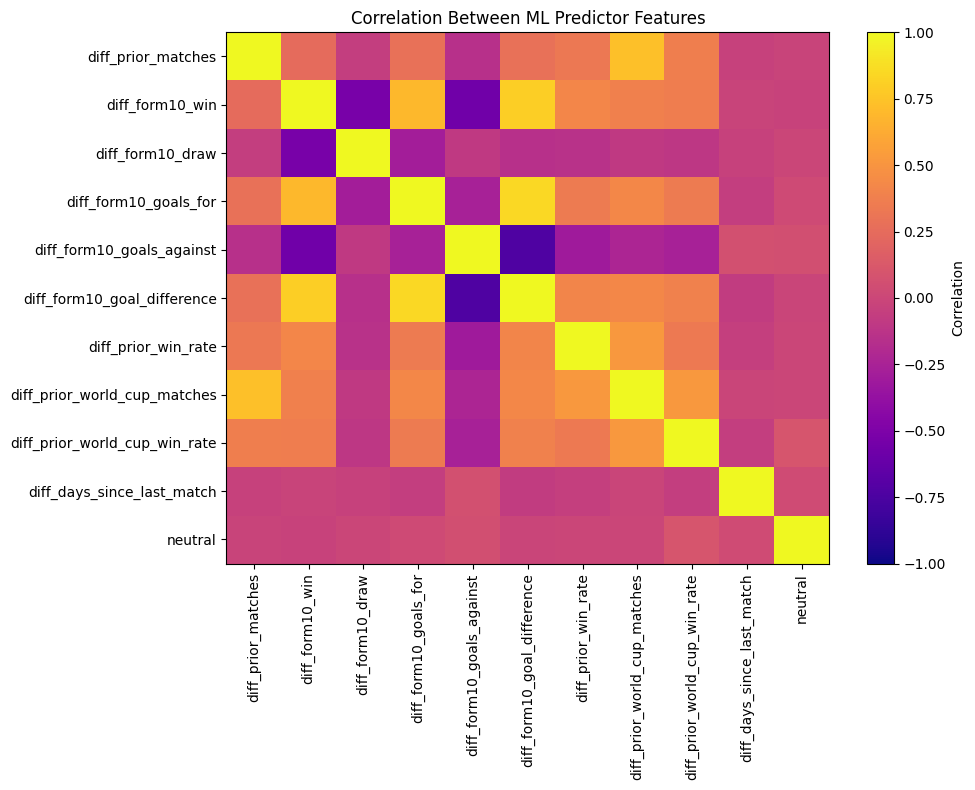

In [9]:
display(model_data[feature_columns].describe().T)

corr = model_data[feature_columns].corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(
    corr,
    aspect='auto',
    vmin=-1,
    vmax=1,
    cmap='plasma')
ax.set_xticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticks(range(len(corr.index)))
ax.set_yticklabels(corr.index)
ax.set_title('Correlation Between ML Predictor Features')
fig.colorbar(im, ax=ax, label='Correlation')
plt.tight_layout()
plt.show()

## Create chronological development, validation and test sets

The split is deliberately based on tournament year:

- **Development:** World Cups up to and including 2014.
- **Validation:** 2018 World Cup.
- **Final test:** 2022 and 2026 World Cups.

The 2018 tournament is used to compare candidate models. The final test set is kept untouched during model selection.

After selecting a model using 2018, that model is refitted using all available modelling matches through 2018 and evaluated once on 2022/2026.

This is closer to the real forecasting question: **can patterns learned from earlier football predict later World Cups?**

In [10]:
development = model_data[model_data['year'] <= 2014].copy()
validation = model_data[model_data['year'] == 2018].copy()
test = model_data[model_data['year'] >= 2022].copy()

for name, df in [
    ('Development (<=2014)', development),
    ('Validation (2018)', validation),
    ('Final test (2022/2026)', test)
]:
    print(f'{name:24s}: {len(df):4d} matches | years {df.year.min()}–{df.year.max()}')
    print(df['target'].value_counts().to_dict())

assert development['date'].max() < validation['date'].min()
assert validation['date'].max() < test['date'].min()

print('\nChronological ordering check passed.')

Development (<=2014)    :  835 matches | years 1930–2014
{'Home Win': 385, 'Away Win': 264, 'Draw': 186}
Validation (2018)       :   64 matches | years 2018–2018
{'Away Win': 26, 'Home Win': 25, 'Draw': 13}
Final test (2022/2026)  :  168 matches | years 2022–2026
{'Home Win': 77, 'Away Win': 52, 'Draw': 39}

Chronological ordering check passed.


## Define evaluation metrics

Accuracy alone can be misleading when classes are uneven. World Cup data contains more home-labelled wins than draws, for example.

We therefore report:

- **Accuracy:** proportion of all matches predicted correctly.
- **Balanced accuracy:** average recall across the three classes.
- **Macro F1:** calculates F1 separately for Home Win, Draw and Away Win, then gives each class equal weight.
- **Log loss:** evaluates predicted probabilities; lower is better.

**Macro F1 is the primary model-selection metric** because all three match outcomes matter and draws should not be ignored simply because they are less common.

In [11]:
def evaluate_model(model, X, y):
    pred = model.predict(X)
    metrics = {
        'accuracy': accuracy_score(y, pred),
        'balanced_accuracy': balanced_accuracy_score(y, pred),
        'macro_f1': f1_score(y, pred, average='macro')
    }
    if hasattr(model, 'predict_proba'):
        proba = model.predict_proba(X)
        metrics['log_loss'] = log_loss(y, proba, labels=model.classes_)
    else:
        metrics['log_loss'] = np.nan
    return metrics

## Establish a baseline and candidate models

A machine-learning model should beat a simple reference point to demonstrate useful predictive value.

### Baseline
`DummyClassifier(strategy='most_frequent')` always predicts the most common development-set outcome.

### Candidate models
**Multinomial Logistic Regression**
- transparent linear baseline;
- numerical features are standardised;
- class weighting reduces dominance by the most common outcome.

**Random Forest**
- captures non-linear relationships and interactions;
- does not require feature scaling;
- conservative leaf-size settings reduce overfitting.

**Histogram Gradient Boosting**
- another non-linear tree-based method;
- builds trees sequentially to correct previous errors;
- regularisation and shallow leaf structure are used to limit complexity.

We compare models using the same development and validation data. The test set remains untouched.

In [12]:
X_dev = development[feature_columns]
y_dev = development['target']
X_val = validation[feature_columns]
y_val = validation['target']

models = {
    'Dummy baseline': DummyClassifier(strategy='most_frequent'),
    'Logistic regression': Pipeline([
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(
            max_iter=2000,
            class_weight='balanced',
            random_state=RANDOM_STATE
        ))
    ]),
    'Random forest': RandomForestClassifier(
        n_estimators=500,
        min_samples_leaf=5,
        max_features='sqrt',
        class_weight='balanced',
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    'Histogram gradient boosting': HistGradientBoostingClassifier(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=15,
        l2_regularization=1.0,
        random_state=RANDOM_STATE
    )
}

validation_rows = []

for name, model in models.items():
    fitted = clone(model).fit(X_dev, y_dev)
    metrics = evaluate_model(fitted, X_val, y_val)
    validation_rows.append({'model': name, **metrics})

validation_results = (
    pd.DataFrame(validation_rows)
    .sort_values('macro_f1', ascending=False)
    .reset_index(drop=True)
)

display(validation_results)

,model,accuracy,balanced_accuracy,macro_f1,log_loss
0,Random forest,0.453,0.405,0.407,1.049
1,Logistic regression,0.453,0.391,0.389,1.014
2,Histogram gradient boosting,0.453,0.380,0.357,1.405
3,Dummy baseline,0.391,0.333,0.187,21.964


## Compare validation performance visually

The strongest model is selected using **2018 macro F1**, not whichever model happens to have the highest test-set score. This prevents the final test set from influencing model choice.

Saved: 06_ML_plot_02.png


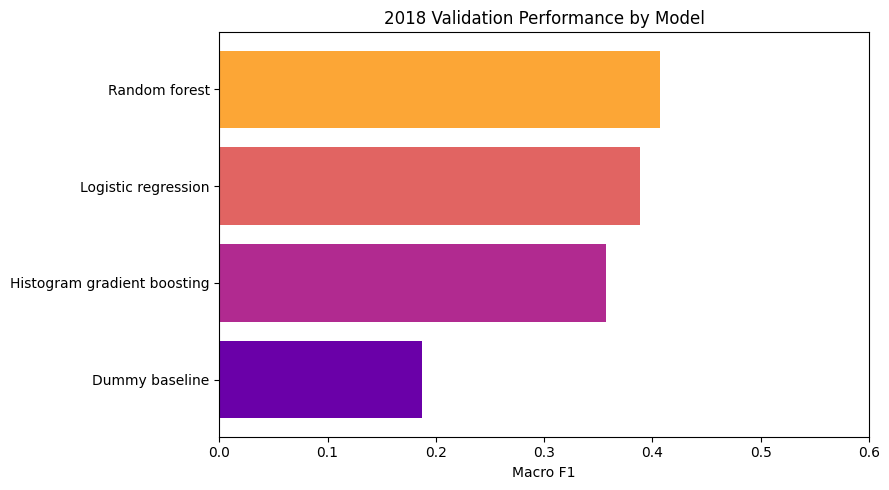

Selected model based on 2018 macro F1: Random forest


In [13]:
fig, ax = plt.subplots(figsize=(9, 5))
plot_data = validation_results.sort_values('macro_f1')
ax.barh(
    plot_data['model'],
    plot_data['macro_f1'],
    color=sns.color_palette('plasma', n_colors=len(plot_data)))
ax.set_xlabel('Macro F1')
ax.set_title('2018 Validation Performance by Model')
ax.set_xlim(0, max(0.6, plot_data['macro_f1'].max() + 0.05))
plt.tight_layout()
plt.show()

selected_model_name = validation_results.iloc[0]['model']
print('Selected model based on 2018 macro F1:', selected_model_name)

### Model-selection interpretation

The selected model is the one that generalised best to the **2018 World Cup** according to macro F1.

A complex model is not automatically preferable. If a simpler model performs as well as or better than a more complex one, the simpler result is valuable evidence that the available pre-match features may not require highly complicated decision boundaries.

Likewise, football is intrinsically uncertain. A modest score does not mean the model has failed; the key comparison is whether it improves meaningfully on the naive baseline while remaining leakage-safe.

## Refit the selected model and evaluate the untouched 2022/2026 test set

Model selection is now complete.

We combine the development data and 2018 validation data, refit the chosen model, and evaluate it on 2022 and 2026. These matches have not been used to choose the algorithm.

This is the notebook's main estimate of out-of-time predictive performance.

In [14]:
train_final = model_data[model_data['year'] <= 2018].copy()

X_train_final = train_final[feature_columns]
y_train_final = train_final['target']
X_test = test[feature_columns]
y_test = test['target']

final_model = clone(models[selected_model_name])
final_model.fit(X_train_final, y_train_final)

test_metrics = evaluate_model(final_model, X_test, y_test)

print('Selected model:', selected_model_name)
print('Final training matches:', len(train_final))
print('Final test matches:', len(test))
print('\nFinal test metrics:')
for metric, value in test_metrics.items():
    print(f'{metric:20s}: {value:.3f}')

Selected model: Random forest
Final training matches: 899
Final test matches: 168

Final test metrics:
accuracy            : 0.554
balanced_accuracy   : 0.522
macro_f1            : 0.517
log_loss            : 0.958


## Comparing the final model with the baseline on the same test set

To interpret the final score fairly, the selected model is compared with a baseline trained on exactly the same pre-2022 data and evaluated on exactly the same 2022/2026 matches.

,model,accuracy,balanced_accuracy,macro_f1,log_loss
0,Dummy baseline,0.458,0.333,0.210,19.524
1,Random forest,0.554,0.522,0.517,0.958


Saved: 06_ML_plot_03.png


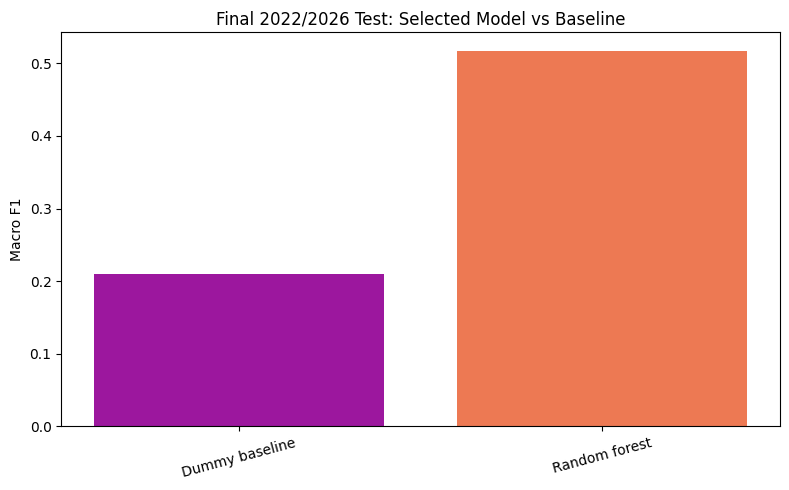

In [15]:
final_baseline = DummyClassifier(strategy='most_frequent')
final_baseline.fit(X_train_final, y_train_final)
baseline_test_metrics = evaluate_model(final_baseline, X_test, y_test)

comparison = pd.DataFrame([
    {'model': 'Dummy baseline', **baseline_test_metrics},
    {'model': selected_model_name, **test_metrics}
])

display(comparison)

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(
    comparison['model'],
    comparison['macro_f1'],
    color=sns.color_palette('plasma', n_colors=len(comparison)))
ax.set_ylabel('Macro F1')
ax.set_title('Final 2022/2026 Test: Selected Model vs Baseline')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## Examine the confusion matrix and class-level performance

Overall metrics can hide which outcomes are difficult to predict.

The confusion matrix shows the actual class against the predicted class. The classification report then gives precision, recall and F1 for each outcome.

Draws are often particularly difficult because a draw sits between two winning outcomes and can be decided by small, unpredictable match events.

Saved: 06_ML_plot_04.png


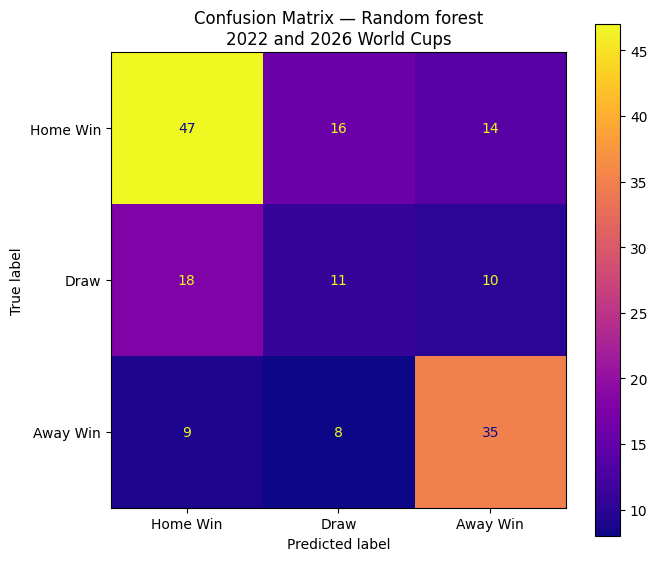

              precision    recall  f1-score   support

    Home Win       0.64      0.61      0.62        77
        Draw       0.31      0.28      0.30        39
    Away Win       0.59      0.67      0.63        52

    accuracy                           0.55       168
   macro avg       0.51      0.52      0.52       168
weighted avg       0.55      0.55      0.55       168



In [16]:
test_predictions = final_model.predict(X_test)

labels = ['Home Win', 'Draw', 'Away Win']
cm = confusion_matrix(y_test, test_predictions, labels=labels)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
fig, ax = plt.subplots(figsize=(7, 6))
disp.plot(
    ax=ax,
    values_format='d',
    cmap='plasma')
ax.set_title(f'Confusion Matrix — {selected_model_name}\n2022 and 2026 World Cups')
plt.tight_layout()
plt.show()

print(classification_report(
    y_test,
    test_predictions,
    labels=labels,
    zero_division=0
))

## Check performance separately for 2022 and 2026

The combined test set is the main evaluation, but tournament-by-tournament results show whether performance is reasonably stable or driven by one competition.

These are **diagnostic results**, not additional opportunities to tune the model.

In [17]:
tournament_test_rows = []

for year in sorted(test['year'].unique()):
    subset = test[test['year'] == year]
    metrics = evaluate_model(
        final_model,
        subset[feature_columns],
        subset['target']
    )
    tournament_test_rows.append({
        'year': int(year),
        'matches': len(subset),
        **metrics
    })

tournament_test_results = pd.DataFrame(tournament_test_rows)
display(tournament_test_results)

,year,matches,accuracy,balanced_accuracy,macro_f1,log_loss
0,2022,64,0.453,0.420,0.415,1.093
1,2026,104,0.615,0.587,0.582,0.875


## Permutation importance: which factors helped prediction?

Permutation importance is model-agnostic.

For each feature, its values are shuffled in the test data while the fitted model stays unchanged. If predictive performance falls substantially, the model was relying on that feature.

We use **macro F1** as the scoring measure to remain consistent with model selection.

Important caution:

> Predictive importance is **not causal importance**.

A feature can help prediction without causing the outcome. Correlated features can also share or dilute importance.

,feature,importance_mean,importance_std
7,diff_prior_world_cup_matches,0.042,0.024
8,diff_prior_world_cup_win_rate,0.038,0.024
0,diff_prior_matches,0.020,0.024
4,diff_form10_goals_against,0.020,0.024
5,diff_form10_goal_difference,0.015,0.029
6,diff_prior_win_rate,0.008,0.018
9,diff_days_since_last_match,0.008,0.005
3,diff_form10_goals_for,0.004,0.014
10,neutral,0.003,0.008
2,diff_form10_draw,-0.004,0.010


Saved: 06_ML_plot_05.png


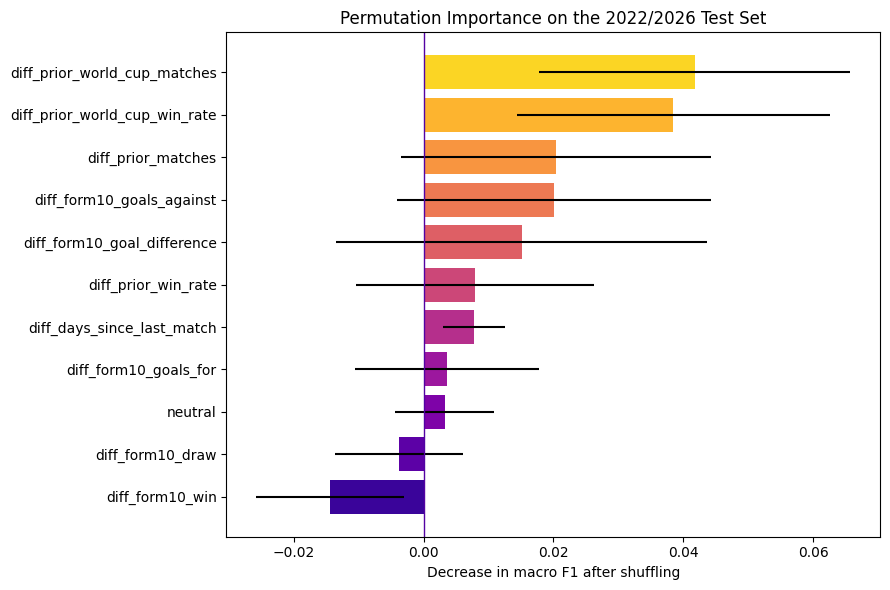

In [18]:
importance = permutation_importance(
    final_model,
    X_test,
    y_test,
    scoring='f1_macro',
    n_repeats=30,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    'feature': feature_columns,
    'importance_mean': importance.importances_mean,
    'importance_std': importance.importances_std
}).sort_values('importance_mean', ascending=False)

display(importance_df)

plot_imp = importance_df.sort_values('importance_mean')

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(
    plot_imp['feature'],
    plot_imp['importance_mean'],
    xerr=plot_imp['importance_std'],
    color=sns.color_palette('plasma', n_colors=len(plot_imp))
)
ax.axvline(0, linewidth=1)
ax.set_xlabel('Decrease in macro F1 after shuffling')
ax.set_title('Permutation Importance on the 2022/2026 Test Set')
plt.tight_layout()
plt.show()

### How to interpret the importance chart

Features near the top with clearly positive permutation importance contained the most useful predictive information for this fitted model and test period.

A value close to zero means shuffling that feature did not materially reduce macro F1. A slightly negative value can occur through sampling variation or redundancy; it does **not** mean the factor is literally harmful in football.

The correct project wording is therefore:

> “These variables carried more predictive information within this model and dataset.”

It would be too strong to say:

> “These variables caused teams to win.”

## Inspect correctly and incorrectly predicted matches

Looking at individual predictions helps keep the evaluation concrete.

Where probability estimates are available, the table includes the model's confidence in its chosen class. Highly confident mistakes are especially useful for understanding limitations.

In [19]:
prediction_table = test[
    ['date', 'home_team', 'away_team', 'target', 'year']
].copy()

prediction_table['predicted'] = test_predictions
prediction_table['correct'] = prediction_table['target'] == prediction_table['predicted']

if hasattr(final_model, 'predict_proba'):
    probabilities = final_model.predict_proba(X_test)
    prediction_table['prediction_confidence'] = probabilities.max(axis=1)

print('Correct predictions:', prediction_table['correct'].sum(), 'of', len(prediction_table))
print('\nSample incorrect predictions:')
display(
    prediction_table[~prediction_table['correct']]
    .sort_values('prediction_confidence', ascending=False)
    .head(15)
)

Correct predictions: 93 of 168

Sample incorrect predictions:


,date,home_team,away_team,target,year,predicted,correct,prediction_confidence
971,2026-06-13,Qatar,Switzerland,Draw,2026,Away Win,False,0.884
956,2022-12-09,Croatia,Brazil,Draw,2022,Away Win,False,0.852
1019,2026-06-25,Ecuador,Germany,Home Win,2026,Away Win,False,0.833
944,2022-12-02,Cameroon,Brazil,Home Win,2022,Away Win,False,0.814
904,2022-11-22,Argentina,Saudi Arabia,Away Win,2022,Home Win,False,0.804
1038,2026-06-29,Germany,Paraguay,Draw,2026,Home Win,False,0.739
979,2026-06-15,Spain,Cape Verde,Draw,2026,Home Win,False,0.700
1009,2026-06-23,England,Ghana,Draw,2026,Home Win,False,0.654
986,2026-06-17,Portugal,DR Congo,Draw,2026,Home Win,False,0.644
917,2022-11-25,Netherlands,Ecuador,Draw,2022,Home Win,False,0.641


## Optional 2026-focused view

Because the project is centred on the 2026 World Cup, this section shows the model's predictions for those matches only.

These predictions are still generated from the same model fitted without 2022/2026 outcomes. No 2026 tournament-total performance statistic is introduced here.

In [20]:
pred_2026 = prediction_table[prediction_table['year'] == 2026].copy()

print('2026 matches evaluated:', len(pred_2026))
print('2026 accuracy:', pred_2026['correct'].mean())

display(pred_2026.head(20))

2026 matches evaluated: 104
2026 accuracy: 0.6153846153846154


,date,home_team,away_team,target,year,predicted,correct,prediction_confidence
964,2026-06-11,Mexico,South Africa,Home Win,2026,Home Win,True,0.717
965,2026-06-11,South Korea,Czech Republic,Home Win,2026,Away Win,False,0.394
966,2026-06-12,Canada,Bosnia and Herzegovina,Draw,2026,Home Win,False,0.473
967,2026-06-12,United States,Paraguay,Home Win,2026,Away Win,False,0.353
968,2026-06-13,Australia,Turkey,Home Win,2026,Away Win,False,0.473
969,2026-06-13,Brazil,Morocco,Draw,2026,Draw,True,0.433
970,2026-06-13,Haiti,Scotland,Away Win,2026,Away Win,True,0.432
971,2026-06-13,Qatar,Switzerland,Draw,2026,Away Win,False,0.884
972,2026-06-14,Germany,Curaçao,Home Win,2026,Home Win,True,0.767
973,2026-06-14,Ivory Coast,Ecuador,Home Win,2026,Away Win,False,0.395


# What does the ML add to the EDA?

The EDA and ML answer related but different questions.

### EDA
The EDA asks:
- which characteristics were associated with stronger tournament performance?
- how did successful and less successful teams differ?
- how were match events such as scoring first associated with outcomes?

### ML
The ML asks:
- can **pre-match information** generalise to future World Cups?
- which pre-match indicators contain useful predictive information when considered together?
- how much better can we do than a naive baseline?

This distinction prevents us from treating post-tournament descriptive statistics as if they had been genuine forecasts.

## Key methodological conclusions

### 1. The model is deliberately leakage-safe
All rolling team features are shifted so the current match cannot contribute to its own predictors. Full-tournament 2026 performance totals are excluded from prediction.

### 2. Evaluation respects time
Model comparison uses 2018, while 2022 and 2026 are held back for final testing. This is more realistic than randomly mixing matches from different eras.

### 3. Multiple metrics are required
Accuracy is reported, but macro F1 and balanced accuracy matter because draws and away wins should not be overwhelmed by the most common class.

### 4. Predictive importance is not causation
Permutation importance tells us which variables the model relied on for prediction. It does not prove that changing those variables would cause a team to win.

### 5. Football retains substantial uncertainty
Match outcomes depend on injuries, tactics, red cards, penalties, individual errors, chance and other information not represented in this dataset. A responsible model should therefore be treated as probabilistic evidence, not certainty.

## Limitations and possible future improvements

This model is intentionally based on variables that can be reconstructed consistently across a long historical period. That makes it safer, but it also limits what the model can know.

Important limitations include:

- historical FIFA rankings are not available in the supplied long-run match dataset;
- detailed xG, passing, physical, movement and defensive metrics are available for 2026 but not consistently for earlier World Cups;
- tactical systems, injuries, squad strength and player-level availability are not modelled;
- football has changed considerably between 1930 and 2026;
- the home/away label in many neutral World Cup matches is administrative rather than a genuine venue advantage;
- historical team identities and political changes complicate very long-run comparisons;
- rolling windows are a modelling choice and could be tuned in future work;
- shootout outcomes are not separately modelled here; the target follows the recorded match score in the cleaned results source.

A stronger future forecasting system could add **historical pre-match FIFA/Elo ratings**, squad/player strength and time-consistent advanced metrics, provided those variables are available as they stood before each match.

## Reproducibility and leakage audit

The final cell records the main dataset sizes, split years, selected model and test performance. It also checks that:

- the development period ends before validation;
- validation ends before the final test;
- no predictor is missing;
- no score or post-match result column appears in the predictor list.

These checks make accidental methodological changes easier to detect if the notebook is rerun later.

In [21]:
forbidden_predictors = {
    'home_score', 'away_score', 'total_goals', 'goal_difference',
    'result', 'target', 'Goals', 'xG', 'GoalsConceded', 'CleanSheets'
}

leaked_names = sorted(set(feature_columns) & forbidden_predictors)

print('=== ML REPRODUCIBILITY / LEAKAGE AUDIT ===')
print('World Cup modelling matches:', len(model_data))
print('Development matches (<=2014):', len(development))
print('Validation matches (2018):', len(validation))
print('Final test matches (2022/2026):', len(test))
print('Number of predictor features:', len(feature_columns))
print('Missing predictor values:', int(model_data[feature_columns].isna().sum().sum()))
print('Forbidden predictor names present:', leaked_names)
print('Selected validation model:', selected_model_name)
print('Final test accuracy:', round(test_metrics['accuracy'], 3))
print('Final test balanced accuracy:', round(test_metrics['balanced_accuracy'], 3))
print('Final test macro F1:', round(test_metrics['macro_f1'], 3))
print('Final test log loss:', round(test_metrics['log_loss'], 3))

assert development['date'].max() < validation['date'].min()
assert validation['date'].max() < test['date'].min()
assert model_data[feature_columns].isna().sum().sum() == 0
assert leaked_names == []

print('\nAll final chronology, missingness and named leakage checks passed.')

=== ML REPRODUCIBILITY / LEAKAGE AUDIT ===
World Cup modelling matches: 1067
Development matches (<=2014): 835
Validation matches (2018): 64
Final test matches (2022/2026): 168
Number of predictor features: 11
Missing predictor values: 0
Forbidden predictor names present: []
Selected validation model: Random forest
Final test accuracy: 0.554
Final test balanced accuracy: 0.522
Final test macro F1: 0.517
Final test log loss: 0.958

All final chronology, missingness and named leakage checks passed.


# Final interpretation

This notebook tests whether historical form and World Cup experience can help predict later World Cup match outcomes without using information from the future.

The most important result is **not simply the highest accuracy number**. The project should interpret the model alongside:

- its improvement over the dummy baseline;
- macro F1 and balanced accuracy;
- which classes are predicted well or poorly;
- whether performance remains reasonable across both 2022 and 2026;
- permutation importance;
- the limitations of the available features.

Together with `05_EDA.ipynb`, this gives a more complete answer to the research question:

> EDA identifies characteristics and match events associated with success, while ML tests whether leakage-safe pre-match indicators contain enough information to generalise to unseen World Cup outcomes.

The final project conclusion should therefore combine the descriptive EDA evidence with the out-of-time ML evidence rather than treating either one in isolation.